# 7 — An interacting ring with an exact g(x, x')

Notebook 6 put an interaction in a trap. Here the same steps run on a **ring** of
length L, using the **Sutherland model** (Calogero–Sutherland on a circle):

    H = -sum_i d^2/dx_i^2 + sum_{i<j} 2 lam (lam - 1) (pi/L)^2 / sin^2(pi (x_i - x_j)/L),

    psi_0 = prod_{i<j} |sin(pi x_ij / L)|^lam,    E_0 = (pi/L)^2 lam^2 N (N^2 - 1) / 3

(Sutherland, Phys. Rev. A 4, 2019 (1971); conventions as in notebook 5, with
hbar^2/2m = 1).

What changes on a ring:

- **Translation invariance.** The density is uniform, so g(x, x') = g(x - x'): the
  matrix is constant along diagonals. On commensurate k = 2 pi n / L, S(k, k') is
  exactly diagonal; the trap in notebook 6 is what coupled k != k'.
- **No NaN disc.** With a uniform density every bin of g has the same expected count,
  so g fills the whole square.
- **A correlation hole.** For lam > 1 the repulsion makes g(0) = 0, which the
  harmonic springs of notebook 6 could not produce.

In [17]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import warnings
warnings.filterwarnings("ignore")

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
import flax.linen as nn

from qvarnet.analysis.estimators import TrainedWavefunction
from qvarnet.ansatz.jastrow import LogJastrow
from qvarnet.physics.hamiltonian.continuous import CalogeroSutherlandSinHamiltonian

n_particles, lam, L = 6, 2.0, 2 * np.pi
ham = CalogeroSutherlandSinHamiltonian(L=lam, L_box=L, epsilon=1e-12)
E0 = (np.pi / L) ** 2 * lam**2 * n_particles * (n_particles**2 - 1) / 3
print("E_0 =", E0)

E_0 = 70.0


## The exact reference: i.i.d. samples of |psi_0|^2

With theta = 2 pi x / L, |sin(pi x_ij / L)| = |e^{i theta_i} - e^{i theta_j}| / 2, so

    |psi_0|^2 ∝ prod_{i<j} |e^{i theta_i} - e^{i theta_j}|^{2 lam},

which is the **circular beta-ensemble** with beta = 2 lam. It has an exact matrix model
(Killip & Nenciu, IMRN 2004, no. 50). Draw independent Verblunsky coefficients
alpha_k ~ Theta_{beta(N-k-1)+1}, build the sparse unitary CMV matrix from them, and its
eigenvalue angles are *exact, independent* samples of |psi_0|^2 for any N and lam. The
result is statistically exact: no MCMC, no autocorrelation, and the noise is the plain
1/sqrt(M).

Two analytic checks validate the sampler:

- For N = 3, g(r) is a single integral (fix two particles, integrate the third), which a
  periodic quadrature evaluates to machine precision.
- For lam = 1 (free fermions), g(r) = 1 - [sin(N pi r/L) / (N sin(pi r/L))]^2 for any N.

N=3, lam=1.0: max |CbetaE - quadrature| = 0.010
N=3, lam=2.0: max |CbetaE - quadrature| = 0.012
N=6, lam=1: max |CbetaE - free fermions| = 0.004
(statistical noise of these checks: ~0.007)


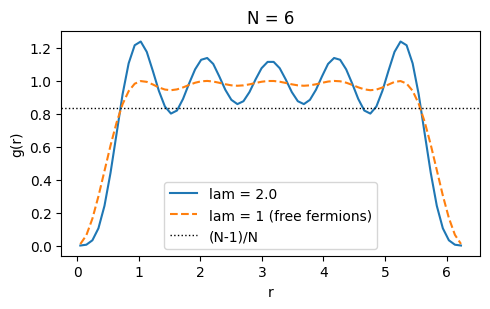

In [18]:
def cbe_samples(N, lam, M, rng):
    """M exact samples (M, N) in [0, L) of |psi_0|^2 = CbetaE with beta = 2 lam (Killip-Nenciu)."""
    beta = 2 * lam
    alpha = np.empty((M, N), complex)
    for k in range(N - 1):
        nu = beta * (N - k - 1) + 1
        r2 = rng.beta(1.0, (nu - 1) / 2, size=M)            # Theta_nu: |alpha|^2 ~ Beta(1, (nu-1)/2)
        alpha[:, k] = np.sqrt(r2) * np.exp(2j * np.pi * rng.random(M))
    alpha[:, N - 1] = np.exp(2j * np.pi * rng.random(M))   # last one on the unit circle
    rho = np.sqrt(np.clip(1 - np.abs(alpha) ** 2, 0, None))

    def blocks(ks, lead_one):
        # block-diagonal of 2x2 Xi_k = [[conj a, rho], [rho, -a]] (1x1 conj a at the edge)
        B = np.zeros((M, N, N), complex)
        if lead_one:
            B[:, 0, 0] = 1.0
        for k in ks:
            B[:, k, k] = alpha[:, k].conj()
            if k + 1 < N:
                B[:, k, k + 1] = B[:, k + 1, k] = rho[:, k]
                B[:, k + 1, k + 1] = -alpha[:, k]
        return B

    cmv = blocks(range(0, N, 2), False) @ blocks(range(1, N, 2), True)
    theta = np.mod(np.angle(np.linalg.eigvals(cmv)), 2 * np.pi)
    return theta * L / (2 * np.pi)


def g_r_hist(x, N, G):
    """g(r) on G bins of [0, L) from samples (M, N); uniform density on the ring."""
    i, j = np.triu_indices(N, 1)
    d = np.mod(x[:, i] - x[:, j], L).ravel()
    h, _ = np.histogram(np.concatenate([d, L - d]), bins=G, range=(0, L))
    return h * G / (len(x) * N**2)          # h / (M N(N-1) w/L) * (N-1)/N


rng = np.random.default_rng(0)
r = np.linspace(0, L, 2048, endpoint=False)
dr = r[1] - r[0]

# check 1: N = 3 against the quadrature
def g_quad_N3(lam):
    R, Y = np.meshgrid(r, r, indexing="ij")
    s = lambda d: np.abs(np.sin(np.pi * d / L)) ** (2 * lam)
    I = (s(R) * s(Y) * s(R - Y)).sum(axis=1)
    return 2 / 3 * L * I / (I.sum() * dr)

G_check = 64
c = (np.arange(G_check) + 0.5) * L / G_check
for lam_c in (1.0, 2.0):
    g_cbe = g_r_hist(cbe_samples(3, lam_c, 400_000, rng), 3, G_check)
    g_q = g_quad_N3(lam_c).reshape(G_check, -1).mean(axis=1)    # bin-averaged
    print(f"N=3, lam={lam_c}: max |CbetaE - quadrature| = {np.max(np.abs(g_cbe - g_q)):.3f}")

# check 2: free fermions at the N actually used
g_cbe = g_r_hist(cbe_samples(n_particles, 1.0, 400_000, rng), n_particles, G_check)
with np.errstate(invalid="ignore", divide="ignore"):
    g_ff = 1 - (np.sin(n_particles * np.pi * r / L) / (n_particles * np.sin(np.pi * r / L))) ** 2
g_ff[0] = 0.0
g_ff = g_ff.reshape(G_check, -1).mean(axis=1)
print(f"N={n_particles}, lam=1: max |CbetaE - free fermions| = {np.max(np.abs(g_cbe - g_ff)):.3f}")
print(f"(statistical noise of these checks: ~{1 / np.sqrt(400_000 * 3 / G_check):.3f})")

# the reference for this notebook
x_exact = cbe_samples(n_particles, lam, 1_000_000, rng)
plt.figure(figsize=(5, 3.2))
plt.plot(c, g_r_hist(x_exact, n_particles, G_check), label=f"lam = {lam}")
plt.plot(c, g_ff, "--", label="lam = 1 (free fermions)")
plt.axhline((n_particles - 1) / n_particles, color="k", ls=":", lw=1, label="(N-1)/N")
plt.xlabel("r"); plt.ylabel("g(r)"); plt.title(f"N = {n_particles}")
plt.legend(); plt.tight_layout(); plt.show()

The reference g and S come from the **same estimator kernels** applied to the exact
i.i.d. samples, on the same bins. Binning is therefore identical, and the only
difference is the wavefunction. With 10^6 independent samples, the reference's own
noise is far below that of the MCMC estimates it is compared to.

On commensurate k, S(k, k') = delta_kk' S(k) exactly. Only the diagonal is physics.

In [19]:
from qvarnet.analysis.estimators import kernels

G = 30
w = L / G
grid = (np.arange(G) + 0.5) * w           # bin centres in [0, L)
idx = (np.arange(G)[:, None] - np.arange(G)[None, :]) % G

_, G_ex = kernels.pair_correlation_grid(x_exact, grid, n_particles, L=L)
gb = np.array([np.nanmean(G_ex[idx == m]) for m in range(G)])   # g(r) from the diagonals

n_k = 15
k_comm = 2 * np.pi * np.arange(1, n_k + 1) / L
_, S_diag = kernels.structure_factor(x_exact, n_particles, k_comm)
assert G_ex.shape == (G, G) and S_diag.shape == (n_k,)

## Step 1 — the estimators on the exact state

The exact psi_0 is a periodic `LogJastrow` with exponent lam and nothing else. First
check E_loc: for an eigenstate it is constant, which tests the Hamiltonian and the
convention for E_0 in one go.

In [20]:
exact_model = LogJastrow(n_particles=n_particles, lambda_init=lam, L=L)
exact_params = exact_model.init(jax.random.PRNGKey(0), jnp.ones((1, n_particles)))

wf_ex = TrainedWavefunction(exact_model, exact_params, n_particles=n_particles,
                            n_dim=1, box_L=L, seed=0)
# step ~ a fraction of the mean spacing L/N; too large a step and the chains stall
wf_ex.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4, step_size=0.3 * L / n_particles)

x = jnp.asarray(wf_ex.samples[:4096])
e_loc = np.asarray(ham.local_energy(exact_params, x, exact_model.apply))
assert e_loc.shape == (4096,)
print(f"E_loc on exact psi: mean {e_loc.mean():.6f}, std {e_loc.std():.2e}   (E_0 = {E0})")

IAT: 104.31  mean ESS: 9.6
E_loc on exact psi: mean 70.000000, std 7.11e-06   (E_0 = 70.0)


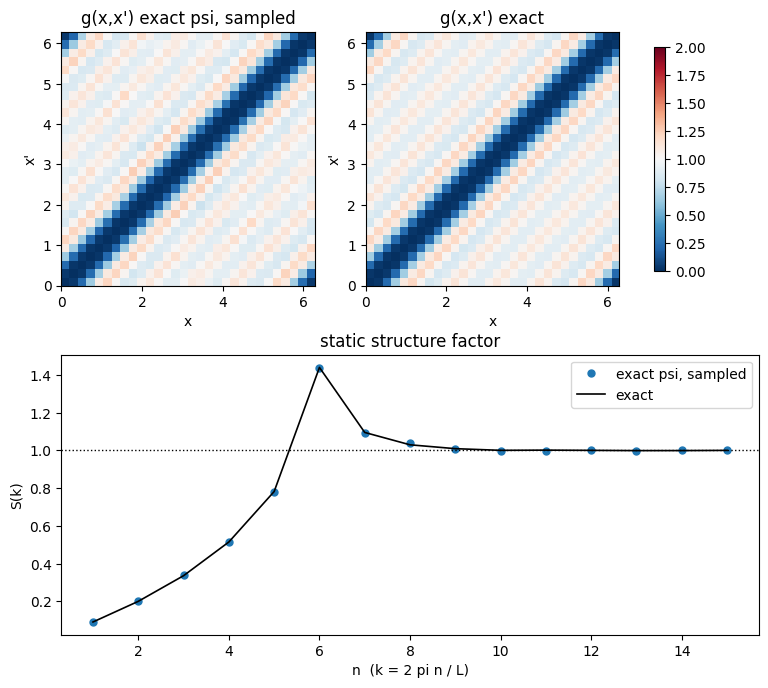

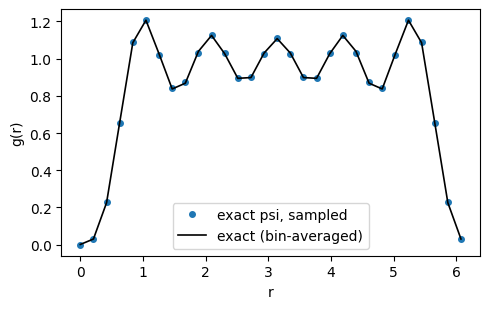

g(x,x'): max |g - exact| = 0.096, rms = 0.018
g(r) from diagonals: max |g - exact| = 0.007
S diagonal: max |S - exact| = 0.008
S(k,k') off-diagonal (exactly 0 by symmetry): max |S| = 0.009


In [21]:
def compare(wf, title):
    """g and S of ``wf`` next to the exact matrices; prints the errors."""
    _, Gm = wf.pair_correlation_grid(grid)
    _, S = wf.structure_factor_matrix(n_max=n_k)

    fig = plt.figure(figsize=(9, 8))
    ax_g = [fig.add_subplot(2, 2, 1), fig.add_subplot(2, 2, 2)]
    for a, m, t in [(ax_g[0], Gm, f"g(x,x') {title}"), (ax_g[1], G_ex, "g(x,x') exact")]:
        im = a.imshow(m.T, origin="lower", extent=[0, L, 0, L], vmin=0.0, vmax=2.0, cmap="RdBu_r")
        a.set(xlabel="x", ylabel="x'", title=t)
    fig.colorbar(im, ax=ax_g, shrink=0.8)
    # translation invariance makes S(k,k') = delta_kk' S(k): only the diagonal is physics
    a = fig.add_subplot(2, 1, 2)
    a.plot(np.arange(1, n_k + 1), np.diag(S).real, "o", ms=5, label=title)
    a.plot(np.arange(1, n_k + 1), S_diag, "k-", lw=1.2, label="exact")
    a.axhline(1.0, color="k", ls=":", lw=1)
    a.set(xlabel="n  (k = 2 pi n / L)", ylabel="S(k)", title="static structure factor")
    a.legend()
    plt.show()

    # translation invariance: average g over each diagonal to get g(r)
    g_r_est = np.array([np.nanmean(Gm[idx == m]) for m in range(G)])
    plt.figure(figsize=(5, 3.2))
    plt.plot(np.arange(G) * w, g_r_est, "o", ms=4, label=title)
    plt.plot(np.arange(G) * w, gb, "k-", lw=1.2, label="exact (bin-averaged)")
    plt.xlabel("r"); plt.ylabel("g(r)"); plt.legend(); plt.tight_layout(); plt.show()

    dg = Gm - G_ex
    off = ~np.eye(n_k, dtype=bool)
    print(f"g(x,x'): max |g - exact| = {np.nanmax(np.abs(dg)):.3f}, rms = {np.sqrt(np.nanmean(dg**2)):.3f}")
    print(f"g(r) from diagonals: max |g - exact| = {np.max(np.abs(g_r_est - gb)):.3f}")
    print(f"S diagonal: max |S - exact| = {np.max(np.abs(np.diag(S).real - S_diag)):.3f}")
    print(f"S(k,k') off-diagonal (exactly 0 by symmetry): max |S| = {np.max(np.abs(S[off])):.3f}")


compare(wf_ex, "exact psi, sampled")

Note the stripes along the diagonals: that is translation invariance. The blue band on
the main diagonal (and its periodic copies in the corners) is the correlation hole, and
the red bands at |x - x'| ≈ L/N, 2L/N, ... show the particles trying to sit equally spaced,
a finite-N precursor of the quasi-crystalline order of the Calogero–Sutherland model.

Only S(k) is plotted. On a ring, S(k, k') = delta_kk' S(k) on the allowed k, so the
off-diagonal carries no information. It stays as a printed symmetry check: anything
above noise (about 1/sqrt(M_eff)) would mean the ansatz or the sampler breaks
translation invariance.

## Step 2 — train a `[16]` MLP

The ansatz is a periodic MLP (sin/cos encoding) times a periodic Jastrow.

**Caveat, the same as in notebook 6:** the Jastrow starts at the exact exponent lam.
The cusp forces this. With any other exponent, the 1/x^2 terms near coincidence fail to
cancel and Var(E_loc) diverges. So the exact state is reachable by the Jastrow alone,
and the MLP's job is to learn to be flat. This tests whether training destroys
structure, not whether a network can build it.

100%|██████████| 3000/3000 [01:20<00:00, 37.23it/s, E=70.0001, sigma_E=0.0085]


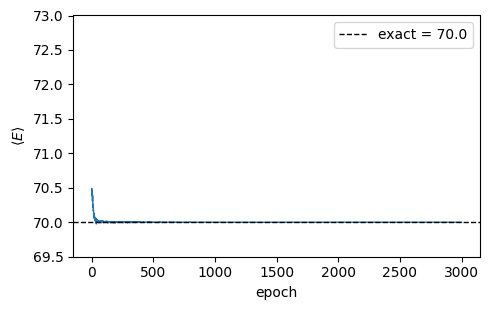

tail energy 69.99997   exact 70.0   tail sigma_E 0.0088


In [22]:
import tempfile
from qvarnet import VMC, SamplingConfig, TrainingConfig
from qvarnet.ansatz.compose import LogWavefunction
from qvarnet.ansatz.mlp import MLP
from qvarnet.physics.boundaries import PeriodicBoundary

psi = LogWavefunction(
    network=MLP(hidden=[16], output_dim=1, hidden_activation=nn.tanh),
    transform=PeriodicBoundary(L),
    jastrow=LogJastrow(n_particles=n_particles, lambda_init=lam, L=L),
)
n_epochs = 3000
result = VMC(
    shape=(2000, n_particles),
    model=psi,
    optimizer=optax.adam(optax.cosine_decay_schedule(5e-3, n_epochs, alpha=0.05)),
    hamiltonian=ham,
    training_config=TrainingConfig(
        n_epochs=n_epochs, rng_seed=0, checkpoint_path=tempfile.mkdtemp(),
        is_update_step_size=True, print_summary=False,
    ),
    sampler_params=SamplingConfig(
        step_size=0.5, chain_length=21, thermalization_steps=20, thinning_factor=1,
        box_L=L,
    ),
).run()

energy = np.asarray(result.history.get("energy"))
std = np.asarray(result.history.get("std"))
plt.figure(figsize=(5, 3.2))
plt.plot(energy, lw=1)
plt.axhline(E0, color="k", ls="--", lw=1, label=f"exact = {E0}")
plt.ylim(E0 - 0.5, E0 + 3); plt.xlabel("epoch"); plt.ylabel(r"$\langle E \rangle$")
plt.legend(); plt.tight_layout(); plt.show()
print(f"tail energy {energy[-100:].mean():.5f}   exact {E0}   tail sigma_E {std[-100:].mean():.4f}")

IAT: 115.58  mean ESS: 12.3


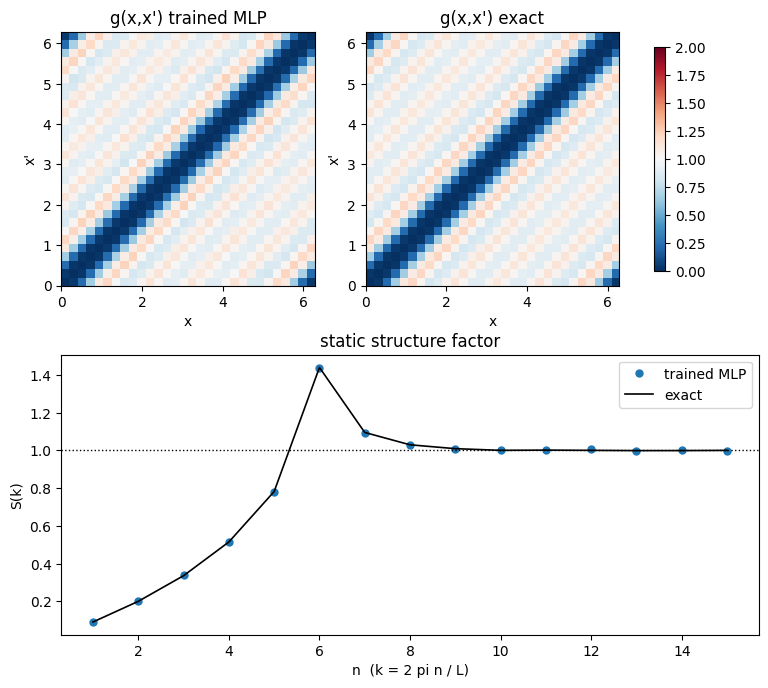

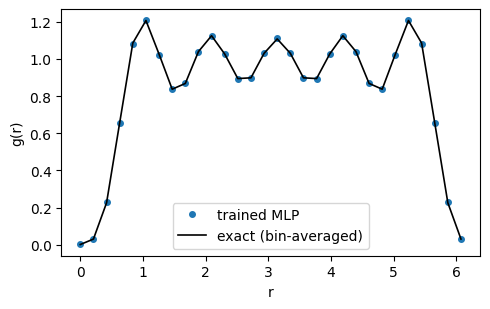

g(x,x'): max |g - exact| = 0.040, rms = 0.013
g(r) from diagonals: max |g - exact| = 0.005
S diagonal: max |S - exact| = 0.005
S(k,k') off-diagonal (exactly 0 by symmetry): max |S| = 0.010


In [23]:
wf_nn = TrainedWavefunction.from_result(psi, result, n_particles, n_dim=1, box_L=L, seed=1)
wf_nn.sample(n_chains=512, n_steps=1000, burn_in=100, thinning=4)
compare(wf_nn, "trained MLP")

## What this does and does not show

- **The reference is validated.** The exact CbetaE sampler matches the N = 3
  quadrature and the free-fermion closed form at the N used, within statistical noise.
  E_loc on the exact psi is constant, so H and E_0 agree.
- **The trained state matches as well:** see the printed energy, sigma_E (the
  zero-variance limit is 0) and the g / S errors. As the caveat above
  says, the Jastrow carries the physics and the MLP only had to stay flat. Unlike in
  notebook 6, training did not wash the structure out.
- **The ring structure is visible directly.** g(x, x') is constant along diagonals,
  the off-diagonal of S(k, k') is at the noise level (the symmetry check), and S(k)
  peaks at n = N, i.e. k = 2 pi rho, the precursor of quasi-long-range order.
- **To make the network do real work,** keep the exact cusp but give the MLP a target
  the Jastrow cannot reach. For example, add an external periodic potential
  V0 cos(2 pi x / L), which needs a one-body factor the Jastrow lacks. No analytic
  reference exists for that, though.
- These are single-seed numbers without error bars.